<a href="https://colab.research.google.com/github/amitpaudel21/BIO_INSPIRED_SYSTEM/blob/main/1BF24CS042_BIS_ANT_COLONY_OPTIMIZATION.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Best route: F -> B -> C -> D -> E -> A -> F
Total distance: 22.54


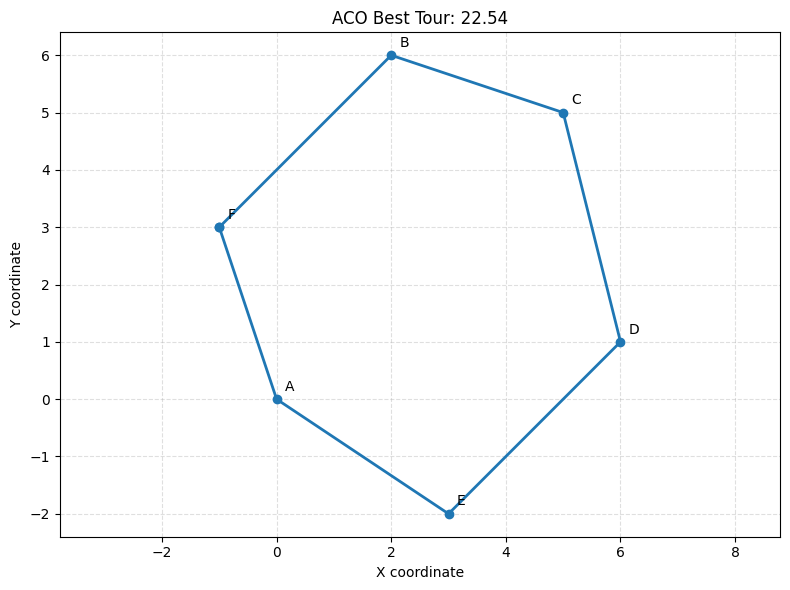

In [1]:

import numpy as np
import matplotlib.pyplot as plt

# Coordinates of six cities
CITY_NAMES = ["A", "B", "C", "D", "E", "F"]

CITIES = np.array([
    [0, 0],
    [2, 6],
    [5, 5],
    [6, 1],
    [3, -2],
    [-1, 3]
], dtype=float)


def distance_matrix(cities):
    difference = (
        cities[:, np.newaxis, :] -
        cities[np.newaxis, :, :]
    )
    distances = np.sqrt(np.sum(difference ** 2, axis=2))
    np.fill_diagonal(distances, 1e-10)
    return distances


def ant_colony_optimization(
    distances, n_ants=30, n_iterations=150,
    alpha=1.0, beta=3.0, evaporation=0.5,
    q=100.0, seed=7
):
    rng = np.random.default_rng(seed)
    n = len(distances)

    # Initialize pheromone and heuristic information
    pheromone = np.ones((n, n))
    heuristic = 1.0 / distances
    np.fill_diagonal(heuristic, 0.0)

    best_tour = None
    best_length = float("inf")

    for iteration in range(n_iterations):
        tours = []
        lengths = []

        # Each ant constructs a complete tour
        for ant in range(n_ants):
            start = int(rng.integers(n))
            tour = [start]
            unvisited = set(range(n))
            unvisited.remove(start)

            while unvisited:
                current = tour[-1]
                candidates = np.array(sorted(unvisited))

                # Probability of selecting each next city
                weights = (
                    pheromone[current, candidates] ** alpha
                    * heuristic[current, candidates] ** beta
                )
                probabilities = weights / weights.sum()

                next_city = int(
                    rng.choice(candidates, p=probabilities)
                )
                tour.append(next_city)
                unvisited.remove(next_city)

            # Return to the starting city
            tour.append(start)

            length = sum(
                distances[tour[i], tour[i + 1]]
                for i in range(len(tour) - 1)
            )

            tours.append(tour)
            lengths.append(length)

            if length < best_length:
                best_length = length
                best_tour = tour.copy()

        # Pheromone evaporation
        pheromone *= (1.0 - evaporation)

        # Reinforce the edges used by each ant
        for tour, length in zip(tours, lengths):
            deposit = q / length

            for i in range(len(tour) - 1):
                a, b = tour[i], tour[i + 1]
                pheromone[a, b] += deposit
                pheromone[b, a] += deposit

    return best_tour, best_length


def plot_tour(cities, names, tour, total_distance):
    route = cities[tour]

    plt.figure(figsize=(8, 6))
    plt.plot(
        route[:, 0], route[:, 1],
        marker="o", linewidth=2
    )

    for i, (x, y) in enumerate(cities):
        plt.annotate(
            names[i], (x, y),
            xytext=(6, 6), textcoords="offset points"
        )

    plt.title(
        f"ACO Best Tour: {total_distance:.2f}"
    )
    plt.xlabel("X coordinate")
    plt.ylabel("Y coordinate")
    plt.grid(True, linestyle="--", alpha=0.4)
    plt.axis("equal")
    plt.tight_layout()
    plt.show()


if __name__ == "__main__":
    distances = distance_matrix(CITIES)

    best_tour, best_length = ant_colony_optimization(
        distances
    )

    print(
        "Best route:",
        " -> ".join(CITY_NAMES[i] for i in best_tour)
    )
    print(f"Total distance: {best_length:.2f}")

    plot_tour(
        CITIES, CITY_NAMES, best_tour, best_length
    )
